# A single coupled poroelastic realization

In [1]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# Governing equations: M. A. Biot (1941), General Theory of Three-Dimensional Consolidation,
# https://doi.org/10.1063/1.1712886. This study uses a two-dimensional finite-element discretization.
# The material input is the realization from Notebook 01, which credits the fBm generator and material laws.

from pathlib import Path
import sys

import numpy as np
from IPython.display import display, Image

root = Path.cwd()
source = root / "src" / "material_sim"
if not (source / "base/fbm500_biot_core.py").is_file():
    raise FileNotFoundError("Open this notebook in the extracted release folder.")
sys.path.insert(0, str(source / "base"))
import fbm500_biot_core as b
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

out = root / "outputs" / "material_sim"
out.mkdir(parents=True, exist_ok=True)
material_file = out / "real_027_material.npz"

In [2]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

from case_setup import build_time_schedule, build_forcing_design
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time

if not material_file.is_file():
    raise FileNotFoundError("Run Notebook 01 to generate outputs/material_sim/real_027_material.npz.")
with np.load(material_file, allow_pickle=False) as mat:
    seed = int(mat["seed"])
    member = int(mat["realization"])
    names = ("logk", "kmd", "phi", "E", "lam", "G", "alpha_mech", "alpha_mass", "S", "mobility")
    coeff = {k: mat[k].copy() for k in names}
assert all(field.shape == (100,100) and np.isfinite(field).all() for field in coeff.values())

In [3]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

NX = NY = 100
KREF_NEW = 1.0
Q_TOTAL = 6e-5
P_LEFT = 1e7
b.K_REF_MD=KREF_NEW
geom=b.Geometry(NX,NY,q_total=Q_TOTAL)
design=build_forcing_design(geom,Q_TOTAL)
q=np.asarray(design.q_matrix[:,0],dtype=np.float64)
times,solver_times,output_ids=build_time_schedule(); lookup={int(v):i for i,v in enumerate(output_ids)}
print("Injection nodes (m):", geom.node_xy[q != 0].tolist())
print("Drainage rows on each side, y (m):", np.unique(geom.node_xy[geom.p_fixed, 1]).tolist())
print(f"{len(solver_times)-1} positive integration steps; {len(times)} saved frames including the initial state.")

Injection nodes (m): [[225.0, 215.0], [225.0, 220.0], [225.0, 225.0], [225.0, 230.0], [225.0, 235.0], [225.0, 240.0]]
Drainage rows on each side, y (m): [165.0, 200.0, 235.0, 265.0, 300.0, 335.0]
70 positive integration steps; 49 saved frames including the initial state.


In [4]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

K,Bm,Ba,M0,H,Tstab,gflow=b.assemble(geom,coeff); M=M0+Tstab
kff=K[geom.u_free][:,geom.u_free].tocsc(); u0=np.zeros(geom.nu)
u0[geom.u_free]=spla.splu(kff).solve((geom.fu+Bm@geom.p0)[geom.u_free])
U=u0.copy(); P=geom.p0.copy()
Pout=np.empty((49,geom.np),np.float32); U1out=np.empty_like(Pout); U2out=np.empty_like(Pout)
Pout[0]=P; U1out[0]=U[0::2]; U2out[0]=U[1::2]
fixed=geom.fixed_global; free=geom.free_global; known=np.zeros(geom.ndof)
known[geom.nu+geom.p_fixed]=P_LEFT/b.P_SCALE
maxres=0.; began=time.time()
for step in range(1,len(solver_times)):
    dt=float(solver_times[step]-solver_times[step-1])
    pblock=M*(b.P_SCALE/dt)+H*b.P_SCALE
    kd=np.abs(K.diagonal()); pd=np.abs(pblock.diagonal())
    scale=float(np.clip(np.median(kd[kd>0])/max(np.median(pd[pd>0]),1e-300),1,1e16))
    A=sp.bmat([[K,-Bm*b.P_SCALE],[Ba.T*(scale/dt),pblock*scale]],format='csr')
    rhs=np.r_[geom.fu,scale*((M@P+Ba.T@U)/dt+gflow+q)]
    Aff=A[free][:,free].tocsc(); rhsf=rhs[free]-A[free][:,fixed]@known[fixed]
    sol=spla.splu(Aff).solve(rhsf)
    res=float(np.linalg.norm(rhsf-Aff@sol,np.inf)/max(np.linalg.norm(rhsf,np.inf),1e-300)); maxres=max(maxres,res)
    if not np.isfinite(sol).all() or res>1e-7: raise RuntimeError((step,res))
    whole=known.copy(); whole[free]=sol; U=whole[:geom.nu]; P=whole[geom.nu:]*b.P_SCALE
    if step in lookup:
        j=lookup[step]; Pout[j]=P; U1out[j]=U[0::2]; U2out[j]=U[1::2]
print(f"Finished {len(solver_times)-1} steps. Maximum scaled linear residual = {maxres:.3e}.")

Finished 70 steps. Maximum scaled linear residual = 9.747e-14.


In [5]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

fields = {"P": Pout, "U1": U1out, "U2": U2out}
sim_file = out / "real_027_forward.npz"
np.savez_compressed(sim_file, **fields, times_s=times, node_xy_m=geom.node_xy,
                    q_vector_m2_s=q, seed=np.int64(seed), realization=np.int64(member))
print(f"Wrote {sim_file.relative_to(root)}")

Wrote outputs/material_sim/real_027_forward.npz


Saved frame indices: [0, 5, 11, 16, 21, 27, 32, 37, 43, 48]


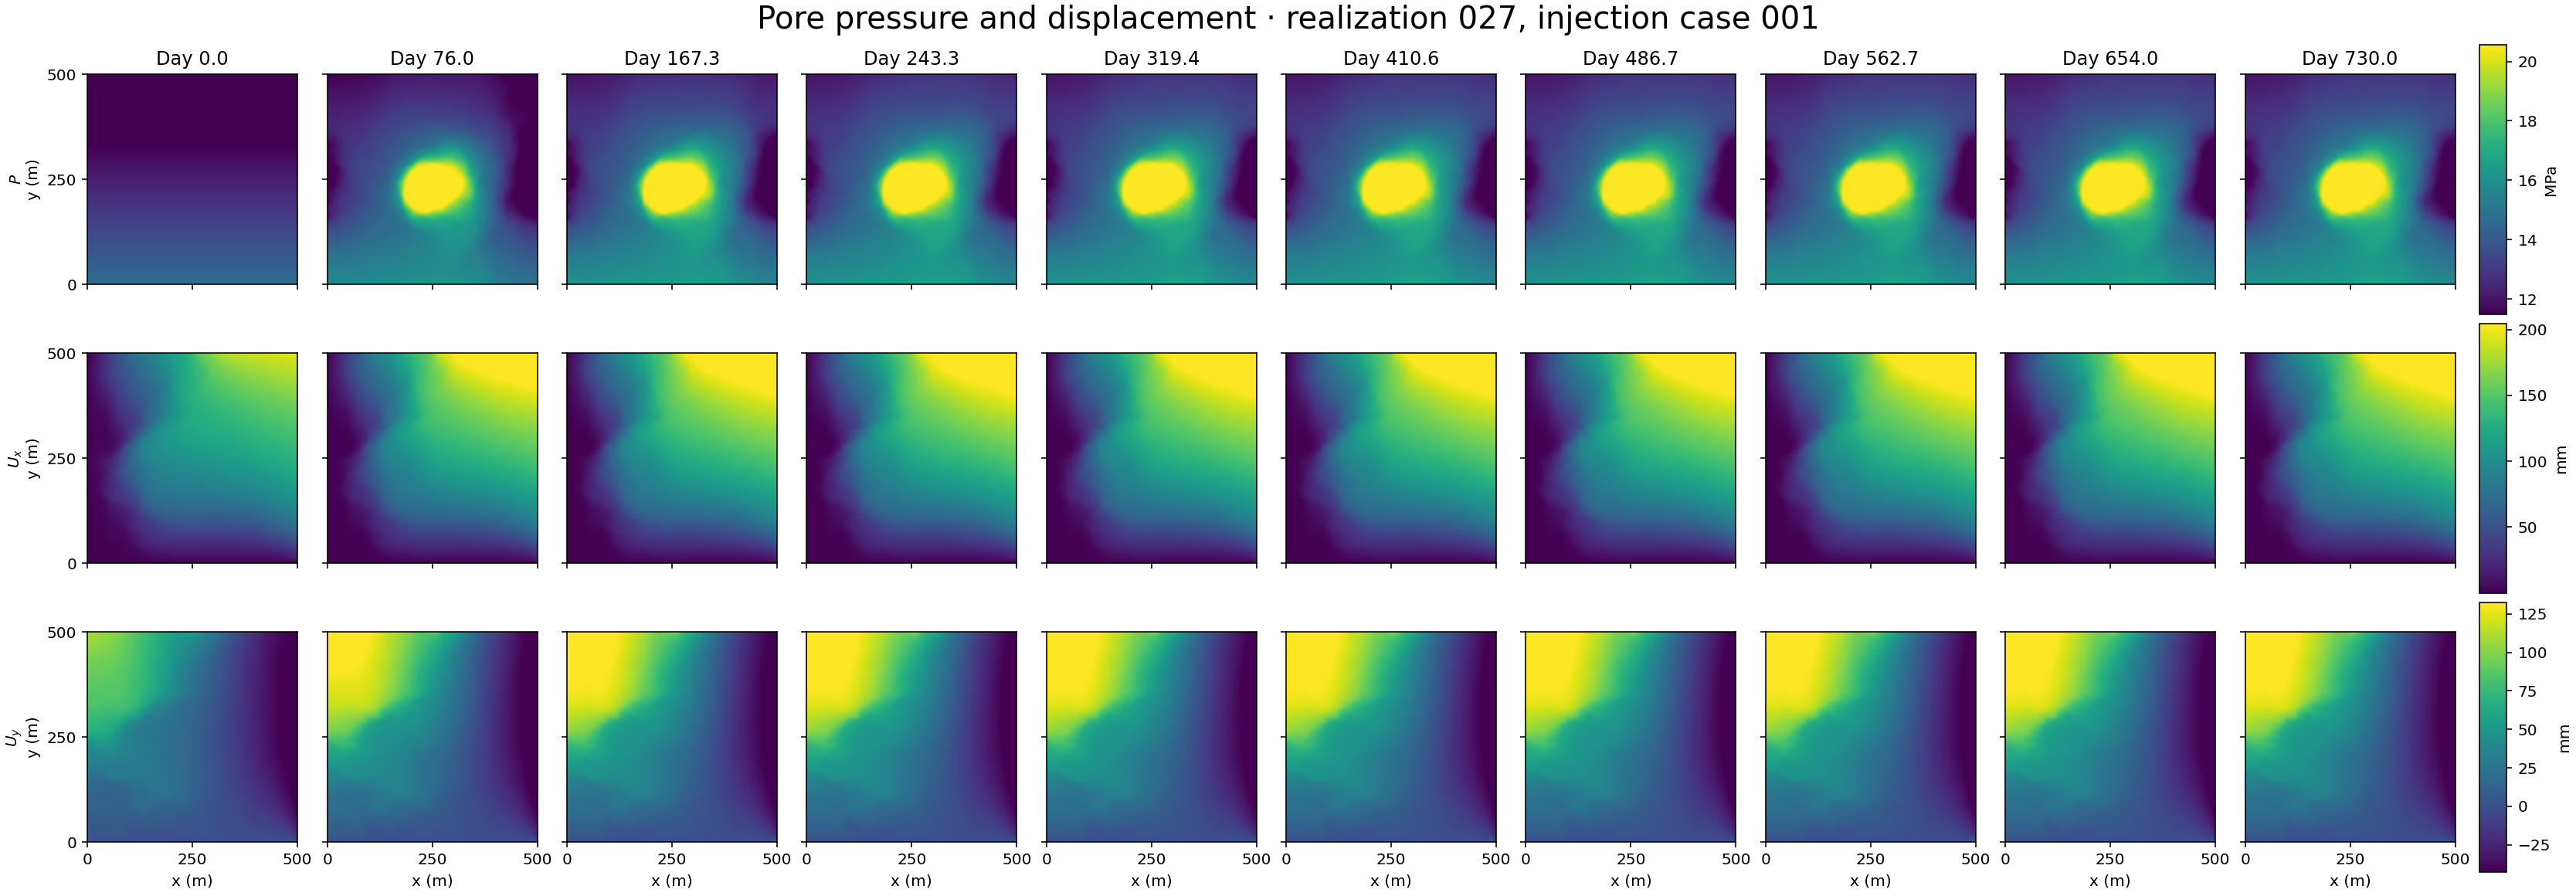

In [6]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

frame_ids = np.rint(np.linspace(0,len(times)-1,10)).astype(int)
rows = [(Pout*1e-6, r"$P$", "MPa"), (U1out*1e3, r"$U_x$", "mm"), (U2out*1e3, r"$U_y$", "mm")]
fig = plt.figure(figsize=(23, 8), constrained_layout=True)
gs = fig.add_gridspec(3,11,width_ratios=[1]*10+[.13])
for i,(data,label,unit) in enumerate(rows):
    lo,hi = np.percentile(data,[5,95])
    for j,f in enumerate(frame_ids):
        ax=fig.add_subplot(gs[i,j])

        image=ax.pcolormesh(geom.x,geom.y,data[f].reshape(101,101),shading="gouraud",cmap="viridis",vmin=lo,vmax=hi,rasterized=True)
        ax.set(aspect="equal", xlim=(0,500), ylim=(0,500), xticks=[0,250,500], yticks=[0,250,500])
        if i == 0: ax.set_title(f"Day {times[f]/86400:.1f}",fontsize=12)
        if i == 2: ax.set_xlabel("x (m)")
        else: ax.tick_params(labelbottom=False)
        if j == 0: ax.set_ylabel(f"{label}\ny (m)")
        else: ax.tick_params(labelleft=False)
    fig.colorbar(image,cax=fig.add_subplot(gs[i,-1]),label=unit)
fig.suptitle("Pore pressure and displacement · realization 027, injection case 001",fontsize=20)
fig_path = out / "real_027_ten_times.png"
fig.savefig(fig_path,dpi=145,facecolor="white")
plt.close(fig)
print("Saved frame indices:", frame_ids.tolist())
display(Image(filename=str(fig_path),width=1450))